[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/03-math/06_eigen-pca.ipynb)

*Math for Data Science & ML · Notebook 6 of 10*

# Eigenvectors, PCA & SVD

The special directions a matrix only stretches. Eigenvalues, power iteration, principal component analysis, singular values, Markov steady states and PageRank.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** Eigenvectors are the directions a matrix only stretches, never turns. PCA keeps the directions where data varies most.

**What interviewers really test here:** Explaining PCA step by step, when to scale, and how to pick components.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Eigenvectors: directions a matrix only stretches *(Basics)*
- [ ] 2. Finding eigenvalues *(Core)*
- [ ] 3. Principal Component Analysis (PCA) *(Core)*
- [ ] 4. Eigenvalues and eigenvectors, fully by hand *(Core)*
- [ ] 5. Power iteration, step by step *(Core)*
- [ ] 6. PCA, fully by hand *(Core)*
- [ ] 7. Orthogonal matrices and diagonalisation *(Advanced)*
- [ ] 8. Singular Value Decomposition (SVD) *(Advanced)*
- [ ] 9. PCA pitfalls *(Advanced)*
- [ ] 10. Diagonalising: powers and steady states by hand *(Advanced)*
- [ ] 11. SVD by hand, and compressing a picture *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Eigenvalues and eigenvectors

For a square matrix A, a non-zero vector v with **Av = λv** is an eigenvector and λ its eigenvalue. The eigenvalues are the roots of the characteristic polynomial **det(A − λI) = 0** (degree n, so n eigenvalues counting repeats, possibly complex).




- Σλᵢ = trace(A), Πλᵢ = det(A). A is invertible ⇔ 0 is not an eigenvalue.
- Triangular matrices: eigenvalues are the diagonal entries.
- Aᵏ has eigenvalues λᵏ with the same eigenvectors; A⁻¹ has 1/λ.
- **Spectral theorem**: a real symmetric matrix has real eigenvalues and an orthonormal set of eigenvectors: A = QΛQᵀ.
- If A has n independent eigenvectors it is **diagonalisable**: A = PDP⁻¹.

### Computing them

| Method | Idea |
| --- | --- |
| Characteristic polynomial | exact for 2 × 2 / 3 × 3 by hand; unstable for large n |
| Power iteration | vₖ₊₁ = Avₖ / ‖Avₖ‖ → dominant eigenvector; converges at rate \|λ₂/λ₁\| |
| QR algorithm | what `np.linalg.eig` uses (LAPACK) |
| `eigh` | faster and more accurate for symmetric matrices; returns ascending order |

### PCA step by step

1. Standardise features if they have different units (otherwise large-scale features dominate).
2. Centre: Xc = X − mean.
3. Covariance C = XcᵀXc/(n − 1) (d × d, symmetric, positive semi-definite).
4. Eigen-decompose C; sort eigenvalues λ₁ ≥ λ₂ ≥ …; eigenvectors are the principal components (loadings).
5. Scores Z = Xc·W\_k (n × k). Reconstruction X̂ = Z·W\_kᵀ + mean.
6. Explained variance ratio λᵢ/Σλ; choose k to keep e.g. 95% (look at a scree plot).



Equivalently via SVD: Xc = UΣVᵀ, the components are the rows of Vᵀ and λᵢ = σᵢ²/(n − 1). PCA is linear and unsupervised; it maximises variance, which is not always what helps prediction.

### Singular Value Decomposition

Every m × n matrix factors as **A = UΣVᵀ**: U (m × m) and V (n × n) orthogonal, Σ diagonal with σ₁ ≥ … ≥ 0. σᵢ = √(eigenvalues of AᵀA). rank(A) = number of non-zero σ. ‖A‖₂ = σ₁; ‖A‖\_F = √Σσᵢ². Truncating to k terms gives the best rank-k approximation with error √(σ²ₖ₊₁ + …) in Frobenius norm. Condition number κ = σ₁/σₙ.

### Where this appears in ML

- PCA for dimensionality reduction and visualisation; whitening.
- Recommenders (matrix factorisation ≈ truncated SVD); latent semantic analysis for text.
- Spectral clustering (eigenvectors of a graph Laplacian), PageRank, Markov chains.
- Stability of training: the Hessian's eigenvalues describe the curvature of the loss (next topics).
- Positive-definite matrices (all λ &gt; 0) — covariance matrices, convex quadratic losses.

---
# Part 2: Lessons, step by step

## Lesson 1: Eigenvectors: directions a matrix only stretches

*Level: Basics*

Multiply most vectors by a matrix and they get **turned** as well as stretched. But some special vectors only get **stretched** (or shrunk, or flipped) — they stay on their own line. These are **eigenvectors** ("own vectors"), and the stretch factor is the **eigenvalue** λ:



**A·v = λ·v**



Example: A = [[2, 1], [1, 2]]. A·[1, 1] = [3, 3] = 3·[1, 1], so [1, 1] is an eigenvector with λ = 3. A·[1, −1] = [1, −1], so λ = 1 there. A·[1, 0] = [2, 1] — turned, so not an eigenvector.



Eigenvectors are a matrix's "natural axes". Along them a complicated transformation becomes simple stretching.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

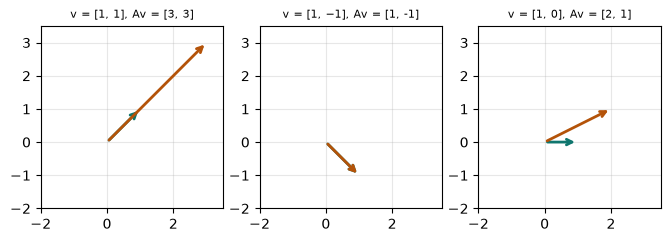

In [2]:
def eigen_picture():
    A = np.array([[2.0, 1.0], [1.0, 2.0]])
    vectors = {"[1, 1]": np.array([1.0, 1.0]), "[1, −1]": np.array([1.0, -1.0]), "[1, 0]": np.array([1.0, 0.0])}
    fig, axes = plt.subplots(1, 3, figsize=(8, 2.8))
    for ax, (name, v) in zip(axes, vectors.items()):
        Av = A @ v
        ax.annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="#0f766e", lw=2))
        ax.annotate("", xy=Av, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="#b45309", lw=2))
        ax.set_xlim(-2, 3.5)
        ax.set_ylim(-2, 3.5)
        ax.set_aspect("equal")
        ax.set_title(f"v = {name}, Av = {Av.astype(int).tolist()}", fontsize=8)
        ax.grid(alpha=0.3)


eigen_picture()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q3](#q3). Try one now, or carry on and do them in Part 3.

## Lesson 2: Finding eigenvalues

*Level: Core*

A·v = λv can be rewritten (A − λI)v = 0. A non-zero v exists only if A − λI squashes space flat, i.e. **det(A − λI) = 0** — the **characteristic equation**.



For a 2 × 2 matrix it is a quadratic: λ² − (trace)λ + det = 0. So the eigenvalues always add up to the trace and multiply to the determinant.



For big matrices we use algorithms instead. The simplest is **power iteration**: multiply any starting vector by A again and again (normalising each time). The biggest eigenvalue wins, and the vector swings round to its eigenvector — this is how Google's original PageRank was computed.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

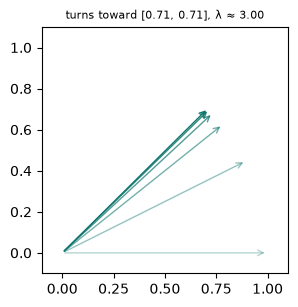

In [3]:
def power_iteration():
    A = np.array([[2.0, 1.0], [1.0, 2.0]])
    v = np.array([1.0, 0.0])
    path = [v]
    for step in range(5):
        v = A @ v
        v = v / np.linalg.norm(v)
        path.append(v)
    estimate = v @ A @ v
    fig, ax = plt.subplots(figsize=(3.5, 3.2))
    for i, p in enumerate(path):
        ax.annotate("", xy=p, xytext=(0, 0), arrowprops=dict(arrowstyle="->", alpha=0.3 + 0.7 * i / 5, color="#0f766e"))
    ax.set_xlim(-0.1, 1.1)
    ax.set_ylim(-0.1, 1.1)
    ax.set_aspect("equal")
    ax.set_title(f"turns toward [0.71, 0.71], λ ≈ {estimate:.2f}", fontsize=8)


power_iteration()

**✏️ Your turn:** you now have what you need for [Q6](#q6), [Q2](#q2), [Q7](#q7), [Q8](#q8). Try one now, or carry on and do them in Part 3.

## Lesson 3: Principal Component Analysis (PCA)

*Level: Core*

Real data often has many correlated features. **PCA** finds new axes, ordered by how much the data spreads along them, so you can keep the few that matter.




1. **Centre** the data: subtract each column's mean.
2. Compute the **covariance matrix** C = XᵀX / (n − 1).
3. Its **eigenvectors** are the principal components; its **eigenvalues** are the variance along each.
4. **Project** the data onto the top k components (scores = X·PC) — fewer numbers, most of the information.



The **explained variance ratio** λᵢ / Σλ tells you what share each component keeps. Uses: compressing data, plotting high-dimensional data in 2-D, removing noise, speeding up models.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

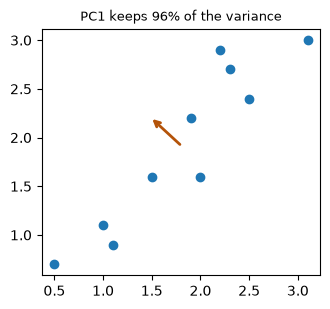

In [4]:
def pca_demo():
    X = np.array([[2.5, 2.4], [0.5, 0.7], [2.2, 2.9], [1.9, 2.2], [3.1, 3.0], [2.3, 2.7], [2, 1.6], [1, 1.1], [1.5, 1.6], [1.1, 0.9]])
    mean = X.mean(axis=0)
    Xc = X - mean
    C = Xc.T @ Xc / (len(X) - 1)
    vals, vecs = np.linalg.eigh(C)
    pc1 = vecs[:, -1]
    ratio = vals[-1] / vals.sum()
    fig, ax = plt.subplots(figsize=(4, 3.2))
    ax.scatter(X[:, 0], X[:, 1])
    for val, vec in zip(vals, vecs.T):
        ax.annotate("", xy=mean + vec * 2 * np.sqrt(val), xytext=mean, arrowprops=dict(arrowstyle="->", color="#b45309", lw=2))
    ax.set_aspect("equal")
    ax.set_title(f"PC1 keeps {ratio:.0%} of the variance", fontsize=9)


pca_demo()

**✏️ Your turn:** you now have what you need for [Q4](#q4), [Q15](#q15), [Q9](#q9), [Q10](#q10), [Q16](#q16). Try one now, or carry on and do them in Part 3.

## Lesson 4: Eigenvalues and eigenvectors, fully by hand

*Level: Core*

A = [[2, 1], [1, 2]].



#### Step 1: find the eigenvalues



Solve det(A − λI) = 0:



```python
det [[2−λ, 1], [1, 2−λ]] = (2−λ)² − 1 = λ² − 4λ + 3 = 0
(λ − 3)(λ − 1) = 0     so λ = 3 or λ = 1
```



**Quick check:** they add to the trace (2 + 2 = 4) and multiply to the determinant (4 − 1 = 3) ✓.



#### Step 2: find each eigenvector



| λ | A − λI | Equation | Eigenvector |
| --- | --- | --- | --- |
| 3 | [[−1, 1], [1, −1]] | −x + y = 0 | (1, 1) |
| 1 | [[1, 1], [1, 1]] | x + y = 0 | (1, −1) |



#### Step 3: verify



A·(1, 1) = (3, 3) = 3·(1, 1) ✓, and A·(1, −1) = (1, −1) = 1·(1, −1) ✓.



**Notes:** any multiple of an eigenvector also works, so (2, 2) is just as valid, and libraries return length-1 versions, with either sign. Here the two eigenvectors are perpendicular, as they always are for a symmetric matrix.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [5]:
def eigen_by_hand():
    A = np.array([[2.0, 1], [1, 2]])
    roots = np.sort(np.roots([1, -4, 3]))
    trace_and_det = (np.trace(A), np.linalg.det(A))
    first = A @ np.array([1.0, 1])
    second = A @ np.array([1.0, -1])
    library_values, library_vectors = np.linalg.eigh(A)
    perpendicular = library_vectors[:, 0] @ library_vectors[:, 1]


eigen_by_hand()

**✏️ Your turn:** you now have what you need for [Q6](#q6), [Q2](#q2), [Q1](#q1), [Q3](#q3). Try one now, or carry on and do them in Part 3.

## Lesson 5: Power iteration, step by step

*Level: Core*

With the same A, start from v = (1, 0). Multiply by A, then rescale to length 1, and repeat.



| Step | A·v | Length | New v | Estimate of λ (v·Av) |
| --- | --- | --- | --- | --- |
| 1 | (2, 1) | 2.236 | (0.894, 0.447) | 2.800 |
| 2 | (2.236, 1.789) | 2.864 | (0.781, 0.625) | 2.976 |
| 3 | (2.186, 2.030) | 2.984 | (0.733, 0.680) | 2.997 |
| 4 | (2.146, 2.094) | 2.998 | (0.716, 0.698) | 3.000 |



v heads towards (0.707, 0.707), and the estimate towards 3.



#### Why it works



Any starting vector is a mix of eigenvectors: here (1, 0) = ½(1, 1) + ½(1, −1). Each multiply stretches the first part by 3 and the second by 1. After k steps the ratio is 3ᵏ to 1, so the first part takes over.



**Speed** depends on |λ₂ / λ₁|: here 1/3, which is fast. When two eigenvalues are close, it's slow.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [6]:
def power_steps():
    A = np.array([[2.0, 1], [1, 2]])
    v = np.array([1.0, 0])
    history = []
    for step in range(6):
        w = A @ v
        v = w / np.linalg.norm(w)
        history.append(round(float(v @ A @ v), 4))
    mix = 0.5 * np.array([1.0, 1]) + 0.5 * np.array([1.0, -1])
    after_ten = 0.5 * 3 ** 10 * np.array([1.0, 1]) + 0.5 * 1 ** 10 * np.array([1.0, -1])
    ratio = after_ten[0] / after_ten[1]


power_steps()

**✏️ Your turn:** you now have what you need for [Q7](#q7), [Q8](#q8). Try one now, or carry on and do them in Part 3.

## Lesson 6: PCA, fully by hand

*Level: Core*

Four rows with two features: (1, 2), (2, 3), (3, 5), (4, 4).



#### Step 1: centre



The means are 2.5 and 3.5, giving (−1.5, −1.5), (−0.5, −0.5), (0.5, 1.5), (1.5, 0.5).



#### Step 2: covariance matrix (divide by n − 1 = 3)



- Var(x) = (2.25 + 0.25 + 0.25 + 2.25) / 3 = 1.667
- Var(y) = (2.25 + 0.25 + 2.25 + 0.25) / 3 = 1.667
- Cov(x, y) = (2.25 + 0.25 + 0.75 + 0.75) / 3 = 1.333



C = [[1.667, 1.333], [1.333, 1.667]].



#### Step 3: eigenvalues and eigenvectors



λ₁ = 1.667 + 1.333 = **3** with direction (0.707, 0.707). λ₂ = 1.667 − 1.333 = **0.333** with direction (0.707, −0.707).



#### Step 4: how much does each keep?



3 / 3.333 = **90%** and 0.333 / 3.333 = 10%. One number can hold 90% of the spread.



#### Step 5: project



Score = centred row · (0.707, 0.707). So (−1.5, −1.5) gives −2.121, and the four scores are −2.121, −0.707, 1.414, 1.414. Two columns became one.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [7]:
def pca_by_hand():
    X = np.array([[1.0, 2], [2, 3], [3, 5], [4, 4]])
    centred = X - X.mean(axis=0)
    C = centred.T @ centred / 3
    values, vectors = np.linalg.eigh(C)
    shares = values[::-1] / values.sum()
    direction = np.array([1.0, 1]) / math.sqrt(2)
    scores = centred @ direction
    rebuilt = X.mean(axis=0) + np.outer(scores, direction)


pca_by_hand()

**✏️ Your turn:** you now have what you need for [Q4](#q4), [Q15](#q15), [Q9](#q9), [Q10](#q10), [Q16](#q16). Try one now, or carry on and do them in Part 3.

## Lesson 7: Orthogonal matrices and diagonalisation

*Level: Advanced*

A symmetric matrix (like a covariance matrix) has **real** eigenvalues and **perpendicular** eigenvectors. Collecting them as columns gives an **orthogonal** matrix Q (QᵀQ = I — a pure rotation), and A = Q·D·Qᵀ with D diagonal.



This **diagonalisation** makes hard things easy: Aⁿ = Q·Dⁿ·Qᵀ (just power the diagonal) — e.g. Fibonacci numbers in one formula, or where a **Markov chain** settles: its steady state is the eigenvector with λ = 1.



**Gram–Schmidt** turns any independent vectors into perpendicular unit vectors; NumPy's QR decomposition does it.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

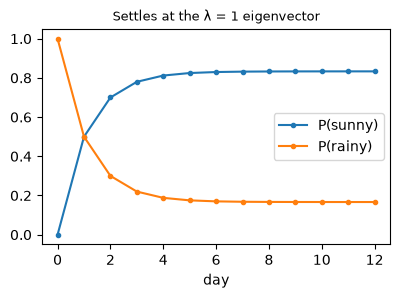

In [8]:
def markov_demo():
    P = np.array([[0.9, 0.1], [0.5, 0.5]])
    state = np.array([0.0, 1.0])
    history = [state]
    for _ in range(12):
        state = state @ P
        history.append(state)
    history = np.array(history)
    fig, ax = plt.subplots(figsize=(4.5, 2.8))
    ax.plot(history[:, 0], "o-", markersize=3, label="P(sunny)")
    ax.plot(history[:, 1], "o-", markersize=3, label="P(rainy)")
    ax.set_xlabel("day")
    ax.legend()
    ax.set_title("Settles at the λ = 1 eigenvector", fontsize=9)


markov_demo()

**✏️ Your turn:** you now have what you need for [Q5](#q5), [Q11](#q11), [Q17](#q17), [Q12](#q12), [Q20](#q20), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 8: Singular Value Decomposition (SVD)

*Level: Advanced*

Eigenvectors need a square matrix. The **SVD** works for **any** matrix: A = U·Σ·Vᵀ — rotate (Vᵀ), stretch along the axes (Σ, the **singular values** σ₁ ≥ σ₂ ≥ … ≥ 0), rotate again (U). The σ's are the square roots of the eigenvalues of AᵀA.




- Keeping only the biggest k singular values gives the **best rank-k approximation** (Eckart–Young) — image compression, recommender systems, LSA for text.
- PCA is the SVD of the centred data matrix.
- σ\_max / σ\_min is the **condition number**: large means the matrix is nearly singular and results are sensitive to rounding.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

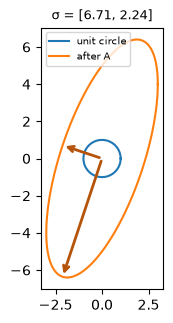

In [9]:
def svd_demo():
    angle = np.linspace(0, 2 * np.pi, 100)
    circle = np.vstack([np.cos(angle), np.sin(angle)])
    A = np.array([[3.0, 0.0], [4.0, 5.0]])
    ellipse = A @ circle
    U, s, Vt = np.linalg.svd(A)
    fig, ax = plt.subplots(figsize=(4, 3.4))
    ax.plot(circle[0], circle[1], label="unit circle")
    ax.plot(ellipse[0], ellipse[1], label="after A")
    for sigma, u in zip(s, U.T):
        ax.annotate("", xy=sigma * u, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="#b45309", lw=2))
    ax.set_aspect("equal")
    ax.legend(fontsize=7)
    ax.set_title(f"σ = {s.round(2).tolist()}", fontsize=9)


svd_demo()

**✏️ Your turn:** you now have what you need for [Q13](#q13), [Q14](#q14), [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 9: PCA pitfalls

*Level: Advanced*

1. **Scale first.** The demo has income (thousands) and age (tens). Unscaled, the first component is simply income, with about 100% of the "variance". After scaling, both matter.
2. **Fit on training data only**, then apply the same means and directions to the test data.
3. **Variance isn't usefulness.** PCA ignores the target. The feature that best predicts y may have low variance and get dropped.
4. **Only straight directions.** Data on a curve won't compress well.
5. **Components are mixtures,** so they're harder to explain. Signs can flip between runs, so don't read meaning into a sign alone.
6. **Outliers distort it,** as squared distances dominate.



#### How many components?



Plot cumulative explained variance and keep enough for, say, 95%. Or choose by testing a downstream model with cross-validation.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [10]:
def pca_scaling():
    r = np.random.default_rng(0)
    age = r.normal(40, 10, 200)
    income = 1000 * age + r.normal(0, 20000, 200)
    X = np.column_stack([income, age])

    def first_direction(data):
        c = data - data.mean(axis=0)
        values, vectors = np.linalg.eigh(c.T @ c)
        return np.abs(vectors[:, -1]).round(3), round(float(values[-1] / values.sum()), 3)

    unscaled = first_direction(X)
    scaled = first_direction((X - X.mean(axis=0)) / X.std(axis=0))


pca_scaling()

<details>
<summary><b>🔎 What happens, step by step</b></summary>

1. first\_direction() returns (array([1., 0.]), 1.0)
2. first\_direction() returns (array([0.707, 0.707]), 0.688)
3. pca\_scaling() returns None

</details>


**✏️ Your turn:** you now have what you need for [Q10](#q10). Try one now, or carry on and do them in Part 3.

## Lesson 10: Diagonalising: powers and steady states by hand

*Level: Advanced*

#### Powers made simple



If A = P D P⁻¹, then in A⁵ the inner P⁻¹P pairs cancel, leaving A⁵ = P D⁵ P⁻¹. Powering a diagonal is easy: just power each entry.



For A = [[2, 1], [1, 2]], with eigenvalues 3 and 1:



- Diagonal entries of A⁵: (3⁵ + 1⁵) / 2 = (243 + 1) / 2 = **122**
- Off-diagonal: (3⁵ − 1⁵) / 2 = 242 / 2 = **121**



#### Markov chain steady state



Sunny stays sunny with chance 0.9; rainy turns sunny with chance 0.5. In the long run, the share π of sunny days must not change:



```python
π = 0.9π + 0.5(1 − π)
0.6π = 0.5
π = 5/6 = 0.833
```



That's the eigenvector of Pᵀ with eigenvalue 1, and it's where the chain settles from any start. PageRank uses the same idea.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [11]:
def diagonalise_demo():
    A = np.array([[2.0, 1], [1, 2]])
    values, P = np.linalg.eigh(A)
    fifth = (P @ np.diag(values ** 5) @ P.T).round(6)
    direct = np.linalg.matrix_power(A, 5)
    T = np.array([[0.9, 0.1], [0.5, 0.5]])
    state = np.array([0.0, 1.0])
    for day in range(40):
        state = state @ T
    long_run = state.round(4)


diagonalise_demo()

**✏️ Your turn:** you now have what you need for [Q17](#q17), [Q12](#q12), [Q5](#q5), [Q11](#q11), [Q20](#q20), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 11: SVD by hand, and compressing a picture

*Level: Advanced*

A = [[3, 0], [4, 5]]. Singular values come from AᵀA:



```python
AᵀA = [[25, 20],
       [20, 25]]
eigenvalues: 25 + 20 = 45 and 25 − 20 = 5
σ₁ = √45 = 6.708     σ₂ = √5 = 2.236
```



They say how much A stretches along its two main directions.



#### Low-rank compression



SVD writes A as a sum of simple layers, biggest first: A = σ₁u₁v₁ᵀ + σ₂u₂v₂ᵀ + … Keep just the first few.



A 100 × 100 picture holds 10,000 numbers. Keeping k layers stores k × (100 + 100 + 1) numbers, so k = 5 needs just 1,005: about a tenth. The demo shows the picture sharpening as k grows.



The same idea powers recommender systems and LSA for text. **PCA is SVD** of the centred data.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

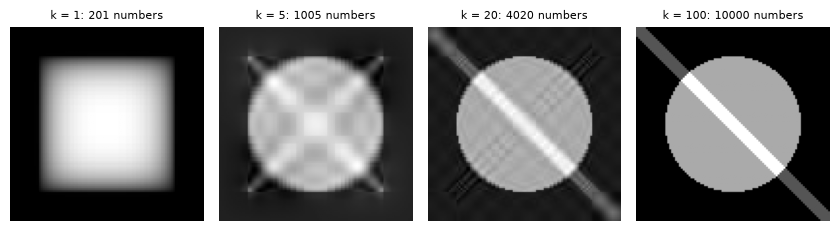

In [12]:
def compress_picture():
    x, y = np.meshgrid(np.linspace(-1, 1, 100), np.linspace(-1, 1, 100))
    picture = (x ** 2 + y ** 2 < 0.5).astype(float) + 0.5 * (np.abs(x - y) < 0.1)
    U, s, Vt = np.linalg.svd(picture)
    fig, axes = plt.subplots(1, 4, figsize=(8.5, 2.3))
    for ax, k in zip(axes, [1, 5, 20, 100]):
        approx = (U[:, :k] * s[:k]) @ Vt[:k]
        ax.imshow(approx, cmap="gray")
        ax.set_title(f"k = {k}: {k * 201 if k < 100 else 10000} numbers", fontsize=8)
        ax.axis("off")
    fig.tight_layout()


compress_picture()

**✏️ Your turn:** you now have what you need for [Q13](#q13), [Q14](#q14), [Q18](#q18). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

<a id="q1"></a>
### Q1. Is It an Eigenvector?

🟢 Warm-up · *A·v = λ·v*

Return λ if v is an eigenvector of A (A·v is v scaled by λ), otherwise None. λ rounded to 4 decimals.

**Examples**

- `A = [[2, 1], [1, 2]], v = [1, 1]` → `3.0`
- `A = [[2, 1], [1, 2]], v = [1, -1]` → `1.0`
- `A = [[2, 1], [1, 2]], v = [1, 0]` → `None`

In [ ]:
def eigen_check(A, v):
    """
    Return λ if v is an eigenvector of A (A·v is v scaled by λ), otherwise None.
    λ rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(eigen_check, [
    (([[2, 1], [1, 2]], [1, 1]), 3.0),
    (([[2, 1], [1, 2]], [1, -1]), 1.0),
    (([[2, 1], [1, 2]], [1, 0]), None),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute A·v by hand, then check every component is the same multiple of v.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

λ = (v·Av)/(v·v); then `np.allclose(A @ v, λ * v)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Compute A·v by hand, then check every component is the same multiple of v.

```python
def eigen_check(A, v):
    Av = [sum(a * x for a, x in zip(row, v)) for row in A]
    ratio = None
    for out, x in zip(Av, v):
        if x == 0:
            if out != 0:
                return None
            continue
        r = out / x
        if ratio is None:
            ratio = r
        elif abs(r - ratio) > 1e-9:
            return None
    return round(ratio, 4)
```

**Cost:** O(n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** λ = (v·Av)/(v·v); then `np.allclose(A @ v, λ * v)`.

```python
def eigen_check(A, v):
    A, v = np.array(A, dtype=float), np.array(v, dtype=float)
    lam = v @ A @ v / (v @ v)
    return round(lam, 4) if np.allclose(A @ v, lam * v) else None
```

**Cost:** O(n²) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute A·v by hand, then check every component is the same multiple of v. That costs O(n²) time and O(n) space."

"I can do better: λ = (v·Av)/(v·v); then `np.allclose(A @ v, λ * v)`. That's O(n²) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/eigen-pca/is-it-an-eigenvector)

<a id="q2"></a>
### Q2. Sum and Product of Eigenvalues

🟢 Warm-up · *trace and determinant*

Return (sum, product) of the eigenvalues of a square matrix, rounded to 4 decimals.

**Examples**

- `A = [[2, 1], [1, 2]]` → `(4.0, 3.0)`
- `A = [[1, 2, 0], [0, 3, 0], [0, 0, 2]]` → `(6.0, 6.0)`

In [ ]:
def eig_sum_prod(A):
    """
    Return (sum, product) of the eigenvalues of a square matrix, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(eig_sum_prod, [
    (([[2, 1], [1, 2]],), (4.0, 3.0)),
    (([[1, 2, 0], [0, 3, 0], [0, 0, 2]],), (6.0, 6.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

No eigenvalues needed: sum = trace, product = determinant (computed by hand).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Compute them and add / multiply: `vals.sum(), vals.prod()`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** No eigenvalues needed: sum = trace, product = determinant (computed by hand).

```python
def eig_sum_prod(A):
    n = len(A)
    trace = sum(A[i][i] for i in range(n))
    M = [list(map(float, r)) for r in A]
    det = 1.0
    for c in range(n):
        p = max(range(c, n), key=lambda r: abs(M[r][c]))
        if M[p][c] == 0:
            return (round(trace, 4), 0.0)
        if p != c:
            M[c], M[p] = M[p], M[c]
            det = -det
        det *= M[c][c]
        for r in range(c + 1, n):
            f = M[r][c] / M[c][c]
            M[r] = [x - f * y for x, y in zip(M[r], M[c])]
    return (round(trace, 4), round(det, 4))
```

**Cost:** O(n) + det time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Compute them and add / multiply: `vals.sum(), vals.prod()`.

```python
def eig_sum_prod(A):
    vals = np.linalg.eigvals(A)
    return (round(vals.sum().real, 4), round(vals.prod().real, 4))
```

**Cost:** O(n³) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: No eigenvalues needed: sum = trace, product = determinant (computed by hand). That costs O(n) + det time and O(1) space."

"I can do better: Compute them and add / multiply: `vals.sum(), vals.prod()`. That's O(n³) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/eigen-pca/sum-and-product-of-eigenvalues)

<a id="q3"></a>
### Q3. Eigenvalues of a Triangular Matrix

🟢 Warm-up · *Read them off the diagonal*

Return the eigenvalues of a triangular (or diagonal) matrix, sorted ascending.

**Examples**

- `A = [[3, 5, 1], [0, 2, 4], [0, 0, 7]]` → `[2, 3, 7]`
- `A = [[1, 0], [9, 4]]` → `[1, 4]`

In [ ]:
def triangular_eigs(A):
    """
    Return the eigenvalues of a triangular (or diagonal) matrix, sorted
    ascending.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(triangular_eigs, [
    (([[3, 5, 1], [0, 2, 4], [0, 0, 7]],), [2, 3, 7]),
    (([[1, 0], [9, 4]],), [1, 4]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

det(A − λI) of a triangular matrix is the product of (diagonal − λ), so the eigenvalues are the diagonal.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.linalg.eigvals` confirms it.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** det(A − λI) of a triangular matrix is the product of (diagonal − λ), so the eigenvalues are the diagonal.

```python
def triangular_eigs(A):
    return sorted(A[i][i] for i in range(len(A)))
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.linalg.eigvals` confirms it.

```python
def triangular_eigs(A):
    return np.sort(np.linalg.eigvals(A).real).round(4)
```

**Cost:** O(n³) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: det(A − λI) of a triangular matrix is the product of (diagonal − λ), so the eigenvalues are the diagonal. That costs O(n log n) time and O(n) space."

"I can do better: `np.linalg.eigvals` confirms it. That's O(n³) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/eigen-pca/eigenvalues-of-a-triangular-matrix)

<a id="q4"></a>
### Q4. Centre the Data

🟢 Warm-up · *PCA step 1*

Subtract each column's mean from that column. Return the centred data rounded to 4 decimals.

**Examples**

- `X = [[1, 2], [2, 3], [3, 5], [4, 4]]` → `[[-1.5, -1.5], [-0.5, -0.5], [0.5, 1.5], [1.5, 0.5]]`

In [ ]:
def centre(X):
    """
    Subtract each column's mean from that column. Return the centred data
    rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(centre, [
    (([[1, 2], [2, 3], [3, 5], [4, 4]],), [[-1.5, -1.5], [-0.5, -0.5], [0.5, 1.5], [1.5, 0.5]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Column means with loops, then subtract.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Broadcasting: `X - X.mean(axis=0)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Column means with loops, then subtract.

```python
def centre(X):
    n, d = len(X), len(X[0])
    means = [sum(row[j] for row in X) / n for j in range(d)]
    return [[round(row[j] - means[j], 4) for j in range(d)] for row in X]
```

**Cost:** O(n·d) time, O(n·d) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Broadcasting: `X - X.mean(axis=0)`.

```python
def centre(X):
    X = np.array(X, dtype=float)
    return (X - X.mean(axis=0)).round(4)
```

**Cost:** O(n·d) time, O(n·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Column means with loops, then subtract. That costs O(n·d) time and O(n·d) space."

"I can do better: Broadcasting: `X - X.mean(axis=0)`. That's O(n·d) time and O(n·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/eigen-pca/centre-the-data)

<a id="q5"></a>
### Q5. Is the Matrix Orthogonal?

🟢 Warm-up · *QᵀQ = I*

Return True if the columns of Q are perpendicular unit vectors (QᵀQ = I, within 1e-6).

**Examples**

- `Q = [[0, -1], [1, 0]]` → `True`
- `Q = [[0.6, -0.8], [0.8, 0.6]]` → `True`
- `Q = [[1, 1], [0, 1]]` → `False`

In [ ]:
def is_orthogonal(Q):
    """
    Return True if the columns of Q are perpendicular unit vectors (QᵀQ = I,
    within 1e-6).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(is_orthogonal, [
    (([[0, -1], [1, 0]],), True),
    (([[0.6, -0.8], [0.8, 0.6]],), True),
    (([[1, 1], [0, 1]],), False),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Check every pair of columns: dot product 1 with itself, 0 with the others.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.allclose(Q.T @ Q, np.eye(n))`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Check every pair of columns: dot product 1 with itself, 0 with the others.

```python
def is_orthogonal(Q):
    n = len(Q)
    for i in range(n):
        for j in range(n):
            d = sum(Q[k][i] * Q[k][j] for k in range(n))
            if abs(d - (1 if i == j else 0)) > 1e-6:
                return False
    return True
```

**Cost:** O(n³) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.allclose(Q.T @ Q, np.eye(n))`.

```python
def is_orthogonal(Q):
    Q = np.array(Q, dtype=float)
    return bool(np.allclose(Q.T @ Q, np.eye(len(Q)), atol=1e-6))
```

**Cost:** O(n³) time, O(n²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Check every pair of columns: dot product 1 with itself, 0 with the others. That costs O(n³) time and O(1) space."

"I can do better: `np.allclose(Q.T @ Q, np.eye(n))`. That's O(n³) time and O(n²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/eigen-pca/is-the-matrix-orthogonal)

<a id="q6"></a>
### Q6. Eigenvalues of a 2×2

🟡 Interview standard · *Characteristic equation*

Return the (real) eigenvalues of a 2×2 matrix, sorted ascending and rounded to 4 decimals.

**Examples**

- `A = [[2, 1], [1, 2]]` → `[1.0, 3.0]`
- `A = [[4, 1], [2, 3]]` → `[2.0, 5.0]`
- `A = [[3, 0], [0, 1]]` → `[1.0, 3.0]`

In [ ]:
def eig2(A):
    """
    Return the (real) eigenvalues of a 2×2 matrix, sorted ascending and rounded
    to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(eig2, [
    (([[2, 1], [1, 2]],), [1.0, 3.0]),
    (([[4, 1], [2, 3]],), [2.0, 5.0]),
    (([[3, 0], [0, 1]],), [1.0, 3.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

det(A − λI) = 0 gives λ² − (trace)λ + det = 0; solve with the quadratic formula.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.linalg.eigvals(A)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** det(A − λI) = 0 gives λ² − (trace)λ + det = 0; solve with the quadratic formula.

```python
def eig2(A):
    (a, b), (c, d) = A
    tr = a + d
    det = a * d - b * c
    disc = math.sqrt(tr * tr - 4 * det)
    return sorted([round((tr - disc) / 2, 4), round((tr + disc) / 2, 4)])
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.linalg.eigvals(A)`.

```python
def eig2(A):
    return np.sort(np.linalg.eigvals(A).real).round(4)
```

**Cost:** O(n³) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: det(A − λI) = 0 gives λ² − (trace)λ + det = 0; solve with the quadratic formula. That costs O(1) time and O(1) space."

"I can do better: `np.linalg.eigvals(A)`. That's O(n³) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/eigen-pca/eigenvalues-of-a-2-2)

<a id="q7"></a>
### Q7. Power Iteration: Biggest Eigenvalue

🟡 Interview standard · *Repeatedly multiply*

Return the eigenvalue of largest size, rounded to 4 decimals.

**Examples**

- `A = [[2, 1], [1, 2]]` → `3.0`
- `A = [[4, 1], [2, 3]]` → `5.0`
- `A = [[3, 0], [0, 1]]` → `3.0`

In [ ]:
def dominant_value(A):
    """
    Return the eigenvalue of largest size, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(dominant_value, [
    (([[2, 1], [1, 2]],), 3.0),
    (([[4, 1], [2, 3]],), 5.0),
    (([[3, 0], [0, 1]],), 3.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Start with any vector, multiply by A and normalise again and again; it turns toward the dominant eigenvector, and v·Av/v·v gives λ.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.linalg.eigvals`, take the one with the largest absolute value.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Start with any vector, multiply by A and normalise again and again; it turns toward the dominant eigenvector, and v·Av/v·v gives λ.

```python
def dominant_value(A):
    v = [1.0] * len(A)
    for _ in range(100):
        w = [sum(a * x for a, x in zip(row, v)) for row in A]
        norm = math.sqrt(sum(x * x for x in w))
        v = [x / norm for x in w]
    Av = [sum(a * x for a, x in zip(row, v)) for row in A]
    return round(sum(x * y for x, y in zip(v, Av)), 4)
```

**Cost:** O(k·n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.linalg.eigvals`, take the one with the largest absolute value.

```python
def dominant_value(A):
    vals = np.linalg.eigvals(A)
    return round(vals[np.argmax(np.abs(vals))].real, 4)
```

**Cost:** O(n³) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Start with any vector, multiply by A and normalise again and again; it turns toward the dominant eigenvector, and v·Av/v·v gives λ. That costs O(k·n²) time and O(n) space."

"I can do better: `np.linalg.eigvals`, take the one with the largest absolute value. That's O(n³) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/eigen-pca/power-iteration-biggest-eigenvalue)

<a id="q8"></a>
### Q8. Power Iteration: Main Direction

🟡 Interview standard · *Dominant eigenvector*

Return the unit eigenvector for the largest eigenvalue, with its first non-zero component positive, rounded to 4 decimals.

**Examples**

- `A = [[2, 1], [1, 2]]` → `[0.7071, 0.7071]`
- `A = [[3, 0], [0, 1]]` → `[1.0, 0.0]`
- `A = [[4, 1], [2, 3]]` → `[0.7071, 0.7071]`

In [ ]:
def dominant_vector(A):
    """
    Return the unit eigenvector for the largest eigenvalue, with its first non-
    zero component positive, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(dominant_vector, [
    (([[2, 1], [1, 2]],), [0.7071, 0.7071]),
    (([[3, 0], [0, 1]],), [1.0, 0.0]),
    (([[4, 1], [2, 3]],), [0.7071, 0.7071]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Power iteration as before, then fix the sign.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.linalg.eig`: pick the column of the biggest eigenvalue.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Power iteration as before, then fix the sign.

```python
def dominant_vector(A):
    v = [1.0] + [0.5] * (len(A) - 1)
    for _ in range(200):
        w = [sum(a * x for a, x in zip(row, v)) for row in A]
        norm = math.sqrt(sum(x * x for x in w))
        v = [x / norm for x in w]
    first = next(x for x in v if abs(x) > 1e-9)
    sign = 1 if first > 0 else -1
    return [round(sign * x, 4) + 0.0 for x in v]
```

**Cost:** O(k·n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.linalg.eig`: pick the column of the biggest eigenvalue.

```python
def dominant_vector(A):
    vals, vecs = np.linalg.eig(np.array(A, dtype=float))
    v = vecs[:, np.argmax(np.abs(vals))].real
    first = v[np.flatnonzero(np.abs(v) > 1e-9)[0]]
    return (np.sign(first) * v).round(4) + 0.0
```

**Cost:** O(n³) time, O(n²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Power iteration as before, then fix the sign. That costs O(k·n²) time and O(n) space."

"I can do better: `np.linalg.eig`: pick the column of the biggest eigenvalue. That's O(n³) time and O(n²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/eigen-pca/power-iteration-main-direction)

<a id="q9"></a>
### Q9. Project Onto the First Component

🟡 Interview standard · *PCA scores*

Centre the data and project each row onto the given unit direction pc. Return the scores rounded to 4 decimals.

**Examples**

- `X = [[1, 2], [2, 3], [3, 5], [4, 4]], pc = [0.7071068, 0.7071068]` → `[-2.1213, -0.7071, 1.4142, 1.4142]`

In [ ]:
def scores(X, pc):
    """
    Centre the data and project each row onto the given unit direction pc.
    Return the scores rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(scores, [
    (([[1, 2], [2, 3], [3, 5], [4, 4]], [0.7071068, 0.7071068]), [-2.1213, -0.7071, 1.4142, 1.4142]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Score of a row = (centred row) · pc, in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`(X - X.mean(0)) @ pc`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Score of a row = (centred row) · pc, in a loop.

```python
def scores(X, pc):
    n, d = len(X), len(X[0])
    means = [sum(r[j] for r in X) / n for j in range(d)]
    out = []
    for r in X:
        out.append(round(sum((r[j] - means[j]) * pc[j] for j in range(d)), 4))
    return out
```

**Cost:** O(n·d) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `(X - X.mean(0)) @ pc`.

```python
def scores(X, pc):
    X = np.array(X, dtype=float)
    return ((X - X.mean(axis=0)) @ np.array(pc)).round(4)
```

**Cost:** O(n·d) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Score of a row = (centred row) · pc, in a loop. That costs O(n·d) time and O(n) space."

"I can do better: `(X - X.mean(0)) @ pc`. That's O(n·d) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/eigen-pca/project-onto-the-first-component)

<a id="q10"></a>
### Q10. Explained Variance Ratio

🟡 Interview standard · *How much each component keeps*

Return each principal component's share of the total variance, largest first, rounded to 4 decimals.

**Examples**

- `X = [[1, 2], [2, 3], [3, 5], [4, 4]]` → `[0.9, 0.1]`

In [ ]:
def explained(X):
    """
    Return each principal component's share of the total variance, largest
    first, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(explained, [
    (([[1, 2], [2, 3], [3, 5], [4, 4]],), [0.9, 0.1]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

2-D covariance by hand, eigenvalues from the characteristic equation, divide by their sum.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`eigh` of the covariance matrix, reverse, divide by the sum.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** 2-D covariance by hand, eigenvalues from the characteristic equation, divide by their sum.

```python
def explained(X):
    n = len(X)
    mx = sum(r[0] for r in X) / n
    my = sum(r[1] for r in X) / n
    a = sum((r[0] - mx) ** 2 for r in X) / (n - 1)
    d = sum((r[1] - my) ** 2 for r in X) / (n - 1)
    b = sum((r[0] - mx) * (r[1] - my) for r in X) / (n - 1)
    tr, det = a + d, a * d - b * b
    disc = math.sqrt(tr * tr - 4 * det)
    l1, l2 = (tr + disc) / 2, (tr - disc) / 2
    return [round(l1 / tr, 4), round(l2 / tr, 4)]
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `eigh` of the covariance matrix, reverse, divide by the sum.

```python
def explained(X):
    vals = np.linalg.eigvalsh(np.cov(np.array(X, dtype=float), rowvar=False))[::-1]
    return (vals / vals.sum()).round(4)
```

**Cost:** O(n·d² + d³) time, O(d²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: 2-D covariance by hand, eigenvalues from the characteristic equation, divide by their sum. That costs O(n) time and O(1) space."

"I can do better: `eigh` of the covariance matrix, reverse, divide by the sum. That's O(n·d² + d³) time and O(d²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/eigen-pca/explained-variance-ratio)

<a id="q11"></a>
### Q11. Gram–Schmidt

🟡 Interview standard · *Make vectors perpendicular*

Turn two independent vectors a, b into an orthonormal pair: e₁ = a/‖a‖, e₂ = (b − proj)/‖…‖. Return [e₁, e₂] rounded to 4 decimals.

**Examples**

- `a = [3, 1], b = [1, 2]` → `[[0.9487, 0.3162], [-0.3162, 0.9487]]`
- `a = [1, 0, 0], b = [1, 1, 0]` → `[[1.0, 0.0, 0.0], [0.0, 1.0, 0.0]]`

In [ ]:
def gram_schmidt(a, b):
    """
    Turn two independent vectors a, b into an orthonormal pair: e₁ = a/‖a‖, e₂ =
    (b − proj)/‖…‖. Return [e₁, e₂] rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(gram_schmidt, [
    (([3, 1], [1, 2]), [[0.9487, 0.3162], [-0.3162, 0.9487]]),
    (([1, 0, 0], [1, 1, 0]), [[1.0, 0.0, 0.0], [0.0, 1.0, 0.0]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Normalise a; subtract b's projection onto e₁; normalise what is left.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

QR decomposition `np.linalg.qr` does Gram–Schmidt; fix signs so R's diagonal is positive.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Normalise a; subtract b's projection onto e₁; normalise what is left.

```python
def gram_schmidt(a, b):
    na = math.sqrt(sum(x * x for x in a))
    e1 = [x / na for x in a]
    proj = sum(x * y for x, y in zip(b, e1))
    r = [x - proj * y for x, y in zip(b, e1)]
    nr = math.sqrt(sum(x * x for x in r))
    e2 = [x / nr for x in r]
    return [[round(x, 4) + 0.0 for x in e1], [round(x, 4) + 0.0 for x in e2]]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** QR decomposition `np.linalg.qr` does Gram–Schmidt; fix signs so R's diagonal is positive.

```python
def gram_schmidt(a, b):
    Q, R = np.linalg.qr(np.array([a, b], dtype=float).T)
    Q = Q * np.sign(np.diag(R))
    return Q.T.round(4) + 0.0
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Normalise a; subtract b's projection onto e₁; normalise what is left. That costs O(n) time and O(n) space."

"I can do better: QR decomposition `np.linalg.qr` does Gram–Schmidt; fix signs so R's diagonal is positive. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/eigen-pca/gram-schmidt)

<a id="q12"></a>
### Q12. Markov Chain Steady State

🟡 Interview standard · *Eigenvector for λ = 1*

Return the long-run distribution π with π·P = π (entries rounded to 4 decimals).

**Examples**

- `P = [[0.9, 0.1], [0.5, 0.5]]` → `[0.8333, 0.1667]`
- `P = [[0.5, 0.5, 0], [0.2, 0.6, 0.2], [0, 0.4, 0.6]]` → `[0.2105, 0.5263, 0.2632]`

In [ ]:
def steady_state(P):
    """
    Return the long-run distribution π with π·P = π (entries rounded to 4
    decimals).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(steady_state, [
    (([[0.9, 0.1], [0.5, 0.5]],), [0.8333, 0.1667]),
    (([[0.5, 0.5, 0], [0.2, 0.6, 0.2], [0, 0.4, 0.6]],), [0.2105, 0.5263, 0.2632]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Start uniform and keep multiplying by P until it stops changing (power iteration).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

The eigenvector of Pᵀ with eigenvalue 1, scaled to sum to 1.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Start uniform and keep multiplying by P until it stops changing (power iteration).

```python
def steady_state(P):
    n = len(P)
    pi = [1 / n] * n
    for _ in range(500):
        pi = [sum(pi[i] * P[i][j] for i in range(n)) for j in range(n)]
    return [round(x, 4) for x in pi]
```

**Cost:** O(k·n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** The eigenvector of Pᵀ with eigenvalue 1, scaled to sum to 1.

```python
def steady_state(P):
    vals, vecs = np.linalg.eig(np.array(P, dtype=float).T)
    v = vecs[:, np.argmin(np.abs(vals - 1))].real
    return (v / v.sum()).round(4)
```

**Cost:** O(n³) time, O(n²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Start uniform and keep multiplying by P until it stops changing (power iteration). That costs O(k·n²) time and O(n) space."

"I can do better: The eigenvector of Pᵀ with eigenvalue 1, scaled to sum to 1. That's O(n³) time and O(n²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/eigen-pca/markov-chain-steady-state)

<a id="q13"></a>
### Q13. Singular Values of a 2×2

🟡 Interview standard · *√ eigenvalues of AᵀA*

Return the singular values of a 2×2 matrix, largest first, rounded to 4 decimals.

**Examples**

- `A = [[3, 0], [4, 5]]` → `[6.7082, 2.2361]`
- `A = [[2, 1], [1, 2]]` → `[3.0, 1.0]`

In [ ]:
def singular_values(A):
    """
    Return the singular values of a 2×2 matrix, largest first, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(singular_values, [
    (([[3, 0], [4, 5]],), [6.7082, 2.2361]),
    (([[2, 1], [1, 2]],), [3.0, 1.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Form AᵀA by hand, find its eigenvalues with the quadratic formula, take square roots.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.linalg.svd(A, compute_uv=False)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Form AᵀA by hand, find its eigenvalues with the quadratic formula, take square roots.

```python
def singular_values(A):
    (a, b), (c, d) = A
    p, q, r = a * a + c * c, a * b + c * d, b * b + d * d
    tr, det = p + r, p * r - q * q
    disc = math.sqrt(tr * tr - 4 * det)
    return [round(math.sqrt((tr + disc) / 2), 4), round(math.sqrt(max(0, (tr - disc) / 2)), 4)]
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.linalg.svd(A, compute_uv=False)`.

```python
def singular_values(A):
    return np.linalg.svd(np.array(A, dtype=float), compute_uv=False).round(4)
```

**Cost:** O(n³) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Form AᵀA by hand, find its eigenvalues with the quadratic formula, take square roots. That costs O(1) time and O(1) space."

"I can do better: `np.linalg.svd(A, compute_uv=False)`. That's O(n³) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/eigen-pca/singular-values-of-a-2-2)

<a id="q14"></a>
### Q14. Condition Number

🟡 Interview standard · *σ\_max / σ\_min*

Return the condition number of a 2×2 matrix (largest / smallest singular value), rounded to 4 decimals. Large means solving A·x = b is sensitive to tiny errors.

**Examples**

- `A = [[3, 0], [4, 5]]` → `3.0`
- `A = [[1, 2], [3, 4]]` → `14.933`

In [ ]:
def condition(A):
    """
    Return the condition number of a 2×2 matrix (largest / smallest singular
    value), rounded to 4 decimals. Large means solving A·x = b is sensitive to
    tiny errors.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(condition, [
    (([[3, 0], [4, 5]],), 3.0),
    (([[1, 2], [3, 4]],), 14.933),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Singular values by hand from AᵀA, then divide.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.linalg.cond(A)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Singular values by hand from AᵀA, then divide.

```python
def condition(A):
    (a, b), (c, d) = A
    p, q, r = a * a + c * c, a * b + c * d, b * b + d * d
    tr, det = p + r, p * r - q * q
    disc = math.sqrt(tr * tr - 4 * det)
    return round(math.sqrt((tr + disc) / (tr - disc)), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.linalg.cond(A)`.

```python
def condition(A):
    return round(np.linalg.cond(np.array(A, dtype=float)), 4)
```

**Cost:** O(n³) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Singular values by hand from AᵀA, then divide. That costs O(1) time and O(1) space."

"I can do better: `np.linalg.cond(A)`. That's O(n³) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/eigen-pca/condition-number)

<a id="q15"></a>
### Q15. First Principal Component

🔴 Stretch · *Direction of greatest spread*

Return the first principal component of 2-D data (unit vector, first component positive, rounded to 4 decimals).

**Examples**

- `X = [[1, 2], [2, 3], [3, 5], [4, 4]]` → `[0.7071, 0.7071]`
- `X = [[2.5, 2.4], [0.5, 0.7], [2.2, 2.9], [1.9, 2.2], [3.1, 3.0], [2.3, 2.7], [2, 1.6], [1, 1.1], [1.5, 1.6], [1.1, 0.9]]` → `[0.6779, 0.7352]`

In [ ]:
def first_pc(X):
    """
    Return the first principal component of 2-D data (unit vector, first
    component positive, rounded to 4 decimals).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(first_pc, [
    (([[1, 2], [2, 3], [3, 5], [4, 4]],), [0.7071, 0.7071]),
    (([[2.5, 2.4], [0.5, 0.7], [2.2, 2.9], [1.9, 2.2], [3.1, 3.0], [2.3, 2.7], [2, 1.6], [1, 1.1], [1.5, 1.6], [1.1, 0.9]],), [0.6779, 0.7352]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Centre, build the covariance matrix by hand, power-iterate to its dominant eigenvector.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.linalg.eigh(np.cov(X, rowvar=False))` — last column is the largest.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Centre, build the covariance matrix by hand, power-iterate to its dominant eigenvector.

```python
def first_pc(X):
    n, d = len(X), len(X[0])
    means = [sum(r[j] for r in X) / n for j in range(d)]
    Xc = [[r[j] - means[j] for j in range(d)] for r in X]
    C = [[sum(r[i] * r[j] for r in Xc) / (n - 1) for j in range(d)] for i in range(d)]
    v = [1.0] * d
    for _ in range(200):
        w = [sum(C[i][j] * v[j] for j in range(d)) for i in range(d)]
        norm = math.sqrt(sum(x * x for x in w))
        v = [x / norm for x in w]
    sign = 1 if v[0] > 0 else -1
    return [round(sign * x, 4) for x in v]
```

**Cost:** O(n·d² + k·d²) time, O(d²) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.linalg.eigh(np.cov(X, rowvar=False))` — last column is the largest.

```python
def first_pc(X):
    vals, vecs = np.linalg.eigh(np.cov(np.array(X, dtype=float), rowvar=False))
    pc = vecs[:, -1]
    return (pc * np.sign(pc[0])).round(4)
```

**Cost:** O(n·d² + d³) time, O(d²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Centre, build the covariance matrix by hand, power-iterate to its dominant eigenvector. That costs O(n·d² + k·d²) time and O(d²) space."

"I can do better: `np.linalg.eigh(np.cov(X, rowvar=False))` — last column is the largest. That's O(n·d² + d³) time and O(d²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/eigen-pca/first-principal-component)

<a id="q16"></a>
### Q16. Compress and Rebuild With One Component

🔴 Stretch · *Dimensionality reduction*

Keep only the first principal component: reconstruct each row as mean + score·pc. Return the rebuilt data rounded to 4 decimals.

**Examples**

- `X = [[1, 2], [2, 3], [3, 5], [4, 4]]` → `[[1.0, 2.0], [2.0, 3.0], [3.5, 4.5], [3.5, 4.5]]`

In [ ]:
def rebuild(X):
    """
    Keep only the first principal component: reconstruct each row as mean +
    score·pc. Return the rebuilt data rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(rebuild, [
    (([[1, 2], [2, 3], [3, 5], [4, 4]],), [[1.0, 2.0], [2.0, 3.0], [3.5, 4.5], [3.5, 4.5]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Centre, find pc by power iteration, score each row, then map back point by point.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Matrix form: `mean + np.outer(Xc @ pc, pc)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Centre, find pc by power iteration, score each row, then map back point by point.

```python
def rebuild(X):
    n, d = len(X), len(X[0])
    means = [sum(r[j] for r in X) / n for j in range(d)]
    Xc = [[r[j] - means[j] for j in range(d)] for r in X]
    C = [[sum(r[i] * r[j] for r in Xc) for j in range(d)] for i in range(d)]
    v = [1.0] * d
    for _ in range(200):
        w = [sum(C[i][j] * v[j] for j in range(d)) for i in range(d)]
        nrm = math.sqrt(sum(x * x for x in w))
        v = [x / nrm for x in w]
    out = []
    for r in Xc:
        s = sum(a * b for a, b in zip(r, v))
        out.append([round(means[j] + s * v[j], 4) for j in range(d)])
    return out
```

**Cost:** O(n·d + k·d²) time, O(n·d) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Matrix form: `mean + np.outer(Xc @ pc, pc)`.

```python
def rebuild(X):
    X = np.array(X, dtype=float)
    mean = X.mean(axis=0)
    Xc = X - mean
    pc = np.linalg.eigh(Xc.T @ Xc)[1][:, -1]
    return (mean + np.outer(Xc @ pc, pc)).round(4)
```

**Cost:** O(n·d) time, O(n·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Centre, find pc by power iteration, score each row, then map back point by point. That costs O(n·d + k·d²) time and O(n·d) space."

"I can do better: Matrix form: `mean + np.outer(Xc @ pc, pc)`. That's O(n·d) time and O(n·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/eigen-pca/compress-and-rebuild-with-one-component)

<a id="q17"></a>
### Q17. Powers by Diagonalising

🔴 Stretch · *Aⁿ = P Dⁿ P⁻¹*

Return Aⁿ (rounded to whole numbers) using its eigen-decomposition.

**Examples**

- `A = [[2, 1], [1, 2]], n = 5` → `[[122, 121], [121, 122]]`
- `A = [[1, 1], [1, 0]], n = 10` → `[[89, 55], [55, 34]]`

In [ ]:
def power_by_eig(A, n):
    """
    Return Aⁿ (rounded to whole numbers) using its eigen-decomposition.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(power_by_eig, [
    (([[2, 1], [1, 2]], 5), [[122, 121], [121, 122]]),
    (([[1, 1], [1, 0]], 10), [[89, 55], [55, 34]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply A by itself n times.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A = PDP⁻¹, so Aⁿ = P·Dⁿ·P⁻¹ — only the diagonal gets powered.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Multiply A by itself n times.

```python
def power_by_eig(A, n):
    k = len(A)
    R = [[1 if i == j else 0 for j in range(k)] for i in range(k)]
    for _ in range(n):
        R = [[sum(R[i][t] * A[t][j] for t in range(k)) for j in range(k)] for i in range(k)]
    return R
```

**Cost:** O(n·k³) time, O(k²) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** A = PDP⁻¹, so Aⁿ = P·Dⁿ·P⁻¹ — only the diagonal gets powered.

```python
def power_by_eig(A, n):
    vals, P = np.linalg.eig(np.array(A, dtype=float))
    An = P @ np.diag(vals ** n) @ np.linalg.inv(P)
    return np.rint(An.real).astype(int)
```

**Cost:** O(k³) time, O(k²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply A by itself n times. That costs O(n·k³) time and O(k²) space."

"I can do better: A = PDP⁻¹, so Aⁿ = P·Dⁿ·P⁻¹ — only the diagonal gets powered. That's O(k³) time and O(k²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/eigen-pca/powers-by-diagonalising)

<a id="q18"></a>
### Q18. Error of the Best Rank-1 Approximation

🔴 Stretch · *Eckart–Young*

Return ‖A − A₁‖ (Frobenius norm) where A₁ is the best rank-1 approximation of the 2×2 matrix A, rounded to 4 decimals.

**Examples**

- `A = [[3, 1], [1, 3]]` → `2.0`
- `A = [[4, 0], [3, -5]]` → `3.1623`

In [ ]:
def rank1_error(A):
    """
    Return ‖A − A₁‖ (Frobenius norm) where A₁ is the best rank-1 approximation
    of the 2×2 matrix A, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(rank1_error, [
    (([[3, 1], [1, 3]],), 2.0),
    (([[4, 0], [3, -5]],), 3.1623),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Build A₁ = σ₁u₁v₁ᵀ by power iteration on AᵀA, subtract from A, take √(sum of squares).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Eckart–Young: the error is just √(σ₂² + …) — the singular values you threw away.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Build A₁ = σ₁u₁v₁ᵀ by power iteration on AᵀA, subtract from A, take √(sum of squares).

```python
def rank1_error(A):
    At_A = [[sum(A[k][i] * A[k][j] for k in range(2)) for j in range(2)] for i in range(2)]
    v = [1.0, 0.3]
    for _ in range(200):
        w = [At_A[0][0] * v[0] + At_A[0][1] * v[1], At_A[1][0] * v[0] + At_A[1][1] * v[1]]
        nrm = math.sqrt(w[0] ** 2 + w[1] ** 2)
        v = [w[0] / nrm, w[1] / nrm]
    Av = [A[0][0] * v[0] + A[0][1] * v[1], A[1][0] * v[0] + A[1][1] * v[1]]
    A1 = [[Av[i] * v[j] for j in range(2)] for i in range(2)]
    err = sum((A[i][j] - A1[i][j]) ** 2 for i in range(2) for j in range(2))
    return round(math.sqrt(err), 4)
```

**Cost:** O(k) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Eckart–Young: the error is just √(σ₂² + …) — the singular values you threw away.

```python
def rank1_error(A):
    s = np.linalg.svd(np.array(A, dtype=float), compute_uv=False)
    return round(np.sqrt((s[1:] ** 2).sum()), 4)
```

**Cost:** O(n³) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Build A₁ = σ₁u₁v₁ᵀ by power iteration on AᵀA, subtract from A, take √(sum of squares). That costs O(k) time and O(1) space."

"I can do better: Eckart–Young: the error is just √(σ₂² + …) — the singular values you threw away. That's O(n³) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/eigen-pca/error-of-the-best-rank-1-approximation)

<a id="q19"></a>
### Q19. PageRank of a Tiny Web

🔴 Stretch · *Eigenvector of the link matrix*

links[j] lists the pages page j links to. With damping 0.85, return each page's PageRank (sums to 1), rounded to 4 decimals.

**Examples**

- `links = [[1, 2], [2], [0]]` → `[0.3878, 0.2148, 0.3974]`
- `links = [[1], [0, 2], [0]]` → `[0.3974, 0.3878, 0.2148]`

In [ ]:
def pagerank(links):
    """
    links[j] lists the pages page j links to. With damping 0.85, return each
    page's PageRank (sums to 1), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(pagerank, [
    (([[1, 2], [2], [0]],), [0.3878, 0.2148, 0.3974]),
    (([[1], [0, 2], [0]],), [0.3974, 0.3878, 0.2148]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Power iteration: every page shares 0.85 of its rank equally among its links, plus 0.15/n for everyone; repeat.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Solve the linear system (I − 0.85·M)·r = 0.15/n directly.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Power iteration: every page shares 0.85 of its rank equally among its links, plus 0.15/n for everyone; repeat.

```python
def pagerank(links):
    n = len(links)
    rank = [1 / n] * n
    for _ in range(200):
        new = [0.15 / n] * n
        for j, outs in enumerate(links):
            for i in outs:
                new[i] += 0.85 * rank[j] / len(outs)
        rank = new
    return [round(r, 4) for r in rank]
```

**Cost:** O(k·links) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Solve the linear system (I − 0.85·M)·r = 0.15/n directly.

```python
def pagerank(links):
    n = len(links)
    M = np.zeros((n, n))
    for j, outs in enumerate(links):
        M[outs, j] = 1 / len(outs)
    r = np.linalg.solve(np.eye(n) - 0.85 * M, np.full(n, 0.15 / n))
    return r.round(4)
```

**Cost:** O(n³) time, O(n²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Power iteration: every page shares 0.85 of its rank equally among its links, plus 0.15/n for everyone; repeat. That costs O(k·links) time and O(n) space."

"I can do better: Solve the linear system (I − 0.85·M)·r = 0.15/n directly. That's O(n³) time and O(n²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/eigen-pca/pagerank-of-a-tiny-web)

<a id="q20"></a>
### Q20. Fibonacci From Eigenvalues

🔴 Stretch · *Binet's formula*

Return the n-th Fibonacci number (F₀ = 0, F₁ = 1).

**Examples**

- `n = 10` → `55`
- `n = 1` → `1`
- `n = 30` → `832040`

In [ ]:
def fibonacci(n):
    """
    Return the n-th Fibonacci number (F₀ = 0, F₁ = 1).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(fibonacci, [
    ((10,), 55),
    ((1,), 1),
    ((30,), 832040),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop: keep the last two numbers.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

[[1, 1], [1, 0]] has eigenvalues φ = (1 + √5)/2 and ψ = (1 − √5)/2, so Fₙ = (φⁿ − ψⁿ)/√5.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Loop: keep the last two numbers.

```python
def fibonacci(n):
    a, b = 0, 1
    for _ in range(n):
        a, b = b, a + b
    return a
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** [[1, 1], [1, 0]] has eigenvalues φ = (1 + √5)/2 and ψ = (1 − √5)/2, so Fₙ = (φⁿ − ψⁿ)/√5.

```python
def fibonacci(n):
    phi, psi = np.linalg.eigvalsh(np.array([[1.0, 1.0], [1.0, 0.0]]))[::-1]
    return int(round((phi ** n - psi ** n) / math.sqrt(5)))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop: keep the last two numbers. That costs O(n) time and O(1) space."

"I can do better: [[1, 1], [1, 0]] has eigenvalues φ = (1 + √5)/2 and ψ = (1 − √5)/2, so Fₙ = (φⁿ − ψⁿ)/√5. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/eigen-pca/fibonacci-from-eigenvalues)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. What is an eigenvector in plain words?</b></summary>

A direction that a matrix does not turn, only stretches. The eigenvalue is the stretch factor (negative means it flips).

</details>

<details>
<summary><b>2. Why does PCA use the covariance matrix's eigenvectors?</b></summary>

The variance of the data projected onto a unit vector w is wᵀCw, which is maximised by the eigenvector with the largest eigenvalue; the next best direction perpendicular to it is the second eigenvector, and so on.

</details>

<details>
<summary><b>3. Should you scale data before PCA?</b></summary>

Yes, when features have different units or ranges. Otherwise the feature with the biggest numbers dominates the first component.

</details>

<details>
<summary><b>4. PCA vs SVD?</b></summary>

PCA is a goal (find directions of maximum variance); SVD of the centred data matrix is the standard way to compute it, avoiding forming XᵀX.

</details>

<details>
<summary><b>5. What does a large condition number mean?</b></summary>

The matrix is close to singular: tiny changes in the input cause large changes in the solution — a warning sign of collinear features in regression.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Eigenvectors: directions a matrix only stretches
- [ ] I can explain: Finding eigenvalues
- [ ] I can explain: Principal Component Analysis (PCA)
- [ ] I can explain: Eigenvalues and eigenvectors, fully by hand
- [ ] I can explain: Power iteration, step by step
- [ ] I can explain: PCA, fully by hand
- [ ] I can explain: Orthogonal matrices and diagonalisation
- [ ] I can explain: Singular Value Decomposition (SVD)
- [ ] I can explain: PCA pitfalls
- [ ] I can explain: Diagonalising: powers and steady states by hand
- [ ] I can explain: SVD by hand, and compressing a picture

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Compress and Rebuild With One Component
- [ ] [Q17](#q17) Powers by Diagonalising
- [ ] [Q18](#q18) Error of the Best Rank-1 Approximation
- [ ] [Q19](#q19) PageRank of a Tiny Web
- [ ] [Q20](#q20) Fibonacci From Eigenvalues

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.